# Examen Práctico: Aprendizaje Federado IID vs. non-IID
**Dataset:** [Air Quality Data Set (UCI / Kaggle)](https://www.kaggle.com/datasets/fedesoriano/air-quality-data-set/data)  
**Arquitectura:** Servidor Federado HTTP/REST + 3 Clientes Distribuidos en Red Local  
**Modelo:** Red Neuronal Multicapa (`FederatedMLP`: $9 \rightarrow 32 \rightarrow 16 \rightarrow 3$, 899 parámetros)  
**Estrategia de Agregación:** Federated Averaging (`FedAvg`, McMahan et al., 2017) con manejo de Timeouts y Resincronización automática.

---

## 1. Definición del Problema, Dataset y Modelo

El dataset **Air Quality** contiene mediciones horarias tomadas por una estación de monitoreo de calidad del aire en una zona urbana de Italia. Tras limpiar los valores faltantes codificados como `-200` y descartar la columna `NMHC(GT)` (ausente en >90% de las filas), se obtienen **7,344 registros válidos**.

### Variables de Entrada ($X$ — 9 características estandarizadas)
1. `PT08.S1(CO)`: Respuesta del sensor químico de óxido de estaño (orientado a CO).
2. `PT08.S2(NMHC)`: Respuesta del sensor químico de titania (orientado a hidrocarburos no metánicos).
3. `PT08.S3(NOx)`: Respuesta del sensor químico de óxido de tungsteno (orientado a $\text{NO}_x$).
4. `PT08.S4(NO2)`: Respuesta del sensor químico de óxido de tungsteno (orientado a $\text{NO}_2$).
5. `PT08.S5(O3)`: Respuesta del sensor químico de óxido de indio (orientado a $\text{O}_3$).
6. `T`: Temperatura ambiental ($^\circ\text{C}$).
7. `RH`: Humedad relativa ($\%$).
8. `AH`: Humedad absoluta.
9. `Hour`: Hora del día ($0\dots 23$).

### Variable Objetivo ($y$ — Clasificación Multiclase en 3 niveles de contaminación por CO)
A partir de la concentración real medida por el analizador de referencia certificado `CO(GT)` ($\text{mg/m}^3$), el problema se formula como la clasificación en **3 niveles de contaminación**:
- **Clase 0 — Bajo ($\text{CO(GT)} \le 1.4\text{ mg/m}^3$):** 2,820 muestras ($38.40\%$)
- **Clase 1 — Medio ($1.4 < \text{CO(GT)} \le 2.5\text{ mg/m}^3$):** 2,263 muestras ($30.81\%$)
- **Clase 2 — Alto ($\text{CO(GT)} > 2.5\text{ mg/m}^3$):** 2,261 muestras ($30.79\%$)

El conjunto de datos se divide en **80% entrenamiento distribuido entre los 3 clientes (5,875 muestras)** y **20% prueba global retenido en el Servidor Federado (1,469 muestras)** para evaluar imparcialmente el modelo global al final de cada ronda.


---
## 2. Arquitectura Federada y Agregación `FedAvg`

```text
                    SERVIDOR (Computadora 1)
                  Modelo Global MLP (w^(t))
                              |
          -----------------------------------------
          |                   |                   |
       Cliente 1           Cliente 2           Cliente 3
    (Computadora 2)     (Computadora 3)     (Computadora 4)
       Datos C1            Datos C2            Datos C3
     Modelo Local        Modelo Local        Modelo Local
          \                   |                   /
               Agregación Ponderada (FedAvg)
                              |
                 Nuevo Modelo Global (w^(t+1))
```

### ¿Qué parámetros se intercambian y cómo se realiza la agregación?
1. **Privacidad:** Los datos locales (`client_1.csv`, `client_2.csv`, `client_3.csv`) jamás abandonan cada computadora cliente.
2. **Parámetros intercambiados (899 números en punto flotante por ronda):**
   - Capa 1: $\mathbf{W}_1 \in \mathbb{R}^{9\times 32}$, $\mathbf{b}_1 \in \mathbb{R}^{32}$ (320 parámetros)
   - Capa 2: $\mathbf{W}_2 \in \mathbb{R}^{32\times 16}$, $\mathbf{b}_2 \in \mathbb{R}^{16}$ (528 parámetros)
   - Capa 3: $\mathbf{W}_3 \in \mathbb{R}^{16\times 3}$, $\mathbf{b}_3 \in \mathbb{R}^{3}$ (51 parámetros)
3. **Ecuación de Agregación (`FedAvg`):**
   En cada ronda $t$, sea $S_t \subseteq \{1, 2, 3\}$ el conjunto de clientes activos que enviaron su actualización antes del `round_timeout`. El servidor actualiza cada tensor de pesos mediante el promedio ponderado por la cantidad de datos locales $n_k$:
   $$\mathbf{w}^{(t+1)} = \sum_{k \in S_t} \alpha_k \, \mathbf{w}_k^{(t+1)}, \qquad \text{donde } \alpha_k = \frac{n_k}{\sum_{j \in S_t} n_j}$$


---
## 3. Demostración de Distribuciones: Escenario 1 (IID) vs. Escenario 2 (non-IID)

- **Escenario 1 (IID):** Muestreo estratificado equitativo. Los 3 clientes poseen el mismo tamaño de muestra ($n \approx 1,958$) y exactamente la misma proporción de clases ($38.4\%$ Bajo, $30.8\%$ Medio, $30.8\%$ Alto).
- **Escenario 2 (non-IID):** Partición fuertemente sesgada por proporción de clases (simulando tres estaciones ubicadas en zonas distintas de la ciudad):
  - **Cliente 1 (Zona Residencial / Baja contaminación):** $92.57\%$ Clase 0 (Bajo), $4.97\%$ Clase 1, $2.46\%$ Clase 2.
  - **Cliente 2 (Zona Urbana Comercial / Contaminación Media):** $8.41\%$ Clase 0, $84.82\%$ Clase 1 (Medio), $6.76\%$ Clase 2.
  - **Cliente 3 (Zona Industrial / Tráfico Pesado / Alta contaminación):** $3.77\%$ Clase 0, $5.99\%$ Clase 1, $90.24\%$ Clase 2 (Alto).


,Escenario,Cliente,Total Muestras,Clase 0 (Bajo),% Bajo,Clase 1 (Medio),% Medio,Clase 2 (Alto),% Alto,Media CO(GT),Media Temp (T)
0,IID,Cliente 1,1958,752,38.41,603,30.80,603,30.80,2.13,0.02
1,IID,Cliente 2,1958,752,38.41,603,30.80,603,30.80,2.14,0.02
2,IID,Cliente 3,1959,752,38.39,604,30.83,603,30.78,2.10,-0.04
3,non-IID,Cliente 1,2193,2030,92.57,109,4.97,54,2.46,1.02,-0.13
4,non-IID,Cliente 2,1878,158,8.41,1593,84.82,127,6.76,1.99,0.16
5,non-IID,Cliente 3,1804,68,3.77,108,5.99,1628,90.24,3.61,-0.01


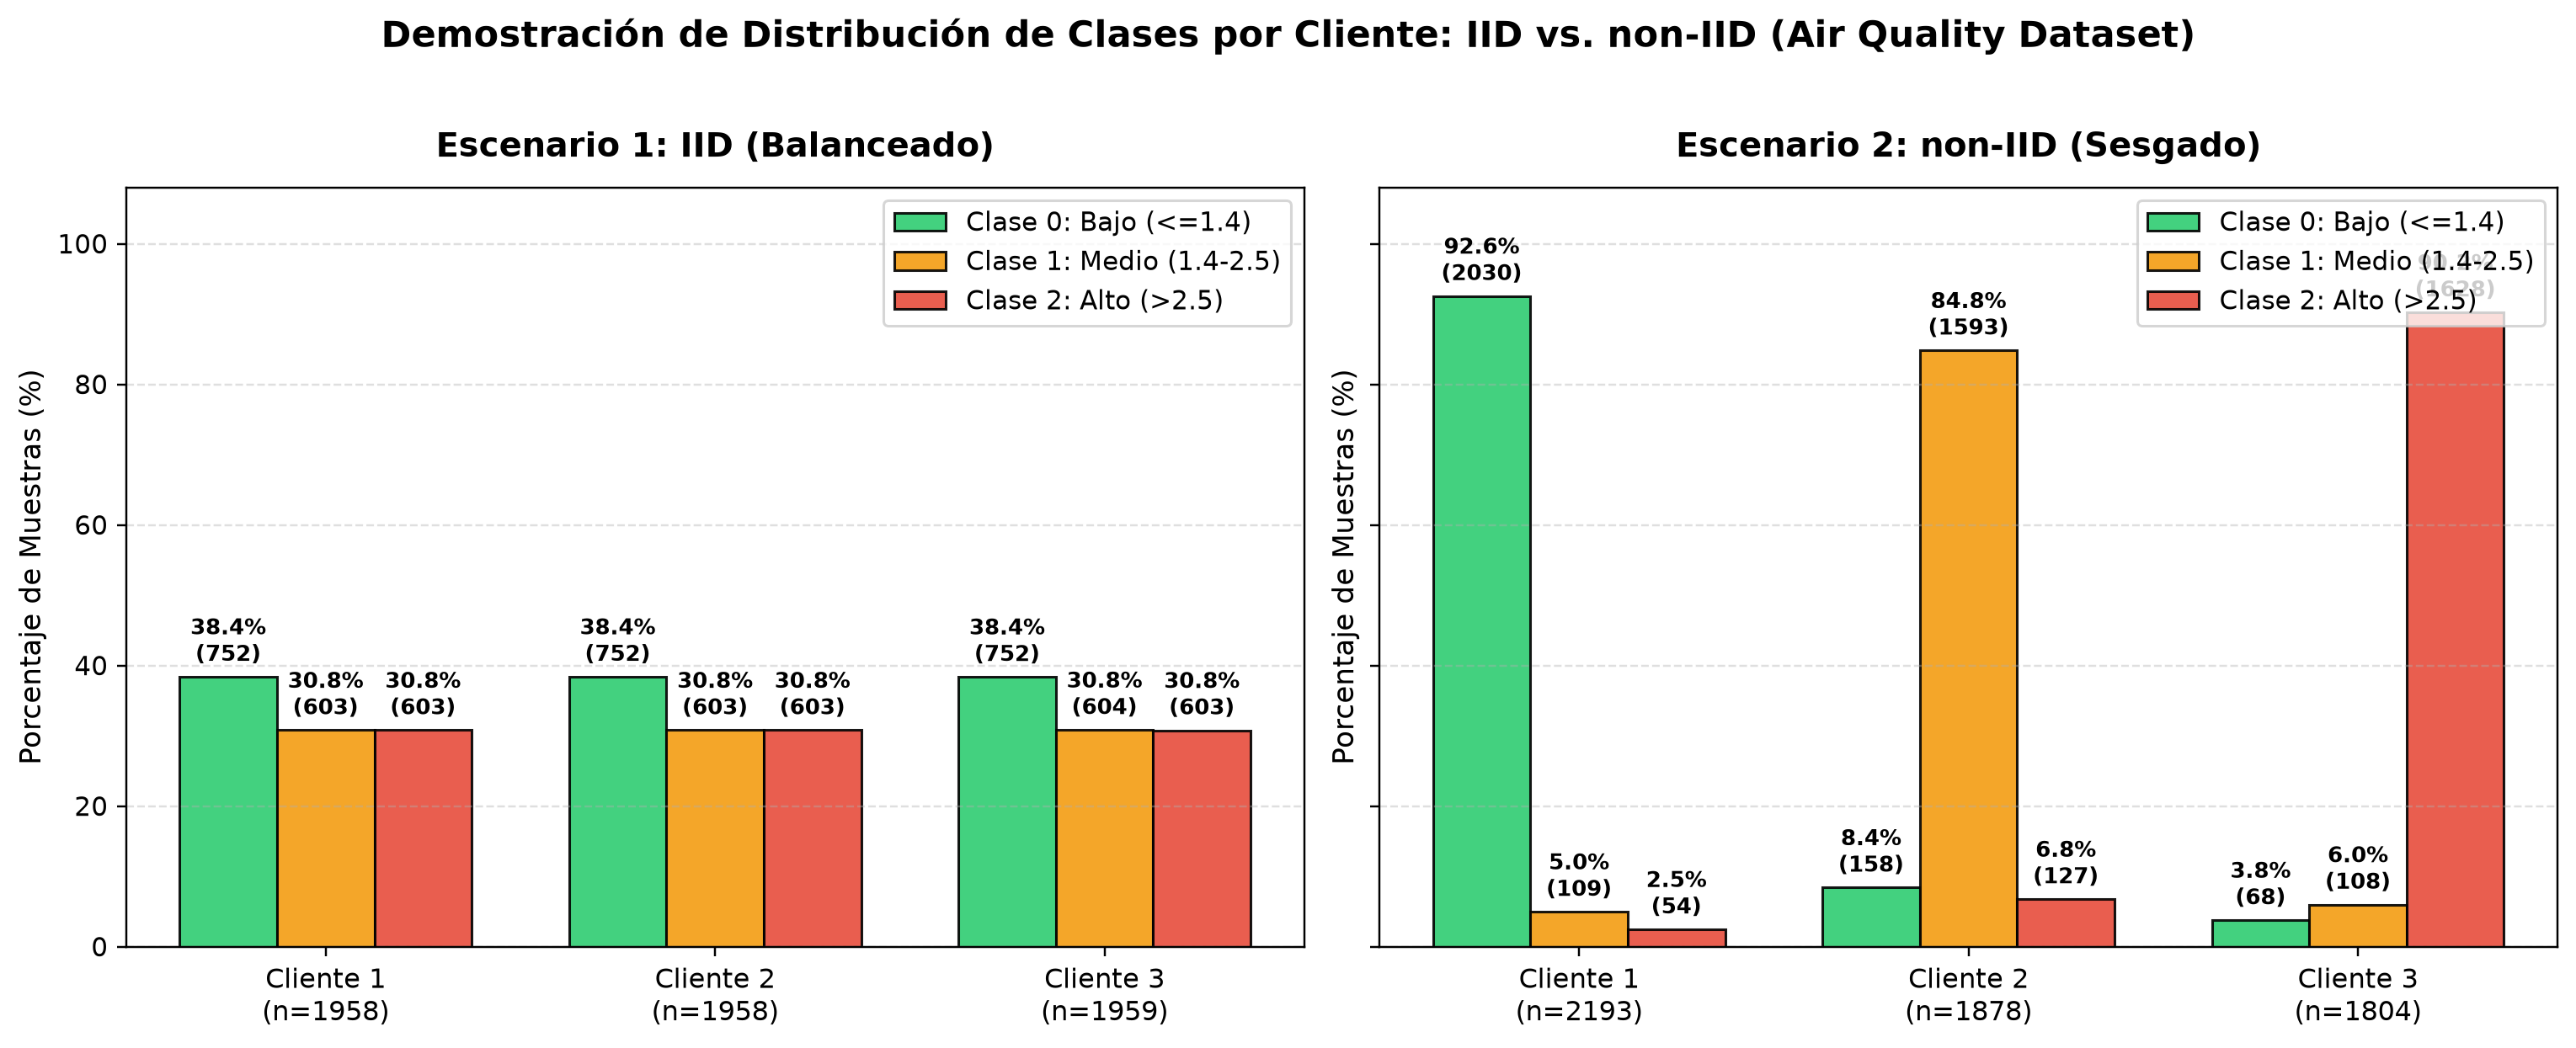

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

dist_df = pd.read_csv("results/tabla_distribucion_clientes.csv")
display(dist_df)
display(Image(filename="results/distribucion_iid_vs_non_iid.png"))


---
## 4. Comparación Experimental: Escenario IID vs. Escenario non-IID (15 Rondas)

Ambos experimentos se ejecutaron con **el mismo modelo inicial** (semilla `seed=42`), **15 rondas federadas**, `local_epochs=10`, `lr=0.03` y `batch_size=64`.


In [2]:
summary_df = pd.read_csv("results/tabla_resumen_final.csv")
print("=== TABLA COMPARATIVA RESUMEN: ESCENARIO IID vs. ESCENARIO non-IID ===")
display(summary_df)

rounds_df = pd.read_csv("results/tabla_comparativa_rondas.csv")
print("=== EVOLUCION DETALLADA POR RONDA (15 RONDAS) ===")
display(rounds_df[[
    "Ronda",
    "IID_Accuracy", "NonIID_Accuracy",
    "IID_Precision", "NonIID_Precision",
    "IID_Recall", "NonIID_Recall",
    "IID_F1", "NonIID_F1",
    "IID_Loss", "NonIID_Loss",
    "IID_Drift_L2", "NonIID_Drift_L2"
]])


=== TABLA COMPARATIVA RESUMEN: ESCENARIO IID vs. ESCENARIO non-IID ===


,Criterio / Metrica,Escenario IID,Escenario non-IID,Diferencia (IID vs non-IID)
0,Accuracy Final (Ronda 15),88.36%,87.00%,+1.36 pp
1,Precision Macro Final (Ronda 15),88.07%,86.76%,+1.31 pp
2,Recall Macro Final (Ronda 15),88.22%,86.73%,+1.49 pp
3,F1-Score Macro Final (Ronda 15),88.14%,86.75%,+1.39 pp
4,Loss Global Final (Cross-Entropy),0.3142,0.3341,-0.0199
5,Divergencia Media de Pesos (Client Drift L2),0.2422,0.5248,2.17x mayor en non-IID
6,Ronda de Convergencia (Acc >= 85%),Ronda 2,Ronda 5,Convergencia mas rapida en IID
7,Oscilacion / Inestabilidad entre Rondas (Std D...,0.00484,0.00186,Mayor estabilidad en IID


=== EVOLUCION DETALLADA POR RONDA (15 RONDAS) ===


,Ronda,IID_Accuracy,NonIID_Accuracy,IID_Precision,NonIID_Precision,IID_Recall,NonIID_Recall,IID_F1,NonIID_F1,IID_Loss,NonIID_Loss,IID_Drift_L2,NonIID_Drift_L2
0,1,0.8380,0.8012,0.8325,0.7966,0.8332,0.7917,0.8316,0.7864,0.4237,0.4986,0.2168,0.8064
1,2,0.8577,0.8319,0.8537,0.8271,0.8545,0.8253,0.8538,0.8248,0.3905,0.4313,0.2217,0.6568
2,3,0.8673,0.8421,0.8639,0.8384,0.8648,0.8374,0.8643,0.8379,0.3728,0.4055,0.2290,0.6100
3,4,0.8700,0.8482,0.8665,0.8439,0.8676,0.8435,0.8670,0.8435,0.3628,0.3900,0.2332,0.5664
4,5,0.8713,0.8550,0.8691,0.8522,0.8691,0.8514,0.8691,0.8518,0.3545,0.3785,0.2386,0.5402
5,6,0.8754,0.8604,0.8729,0.8574,0.8738,0.8560,0.8733,0.8566,0.3479,0.3715,0.2393,0.5304
6,7,0.8802,0.8639,0.8775,0.8613,0.8790,0.8603,0.8781,0.8607,0.3417,0.3635,0.2383,0.5077
7,8,0.8775,0.8652,0.8746,0.8649,0.8757,0.8630,0.8751,0.8635,0.3365,0.3582,0.2417,0.4927
8,9,0.8829,0.8686,0.8802,0.8662,0.8816,0.8659,0.8809,0.8660,0.3318,0.3527,0.2413,0.4763
9,10,0.8795,0.8679,0.8769,0.8673,0.8775,0.8659,0.8772,0.8663,0.3287,0.3495,0.2441,0.4644


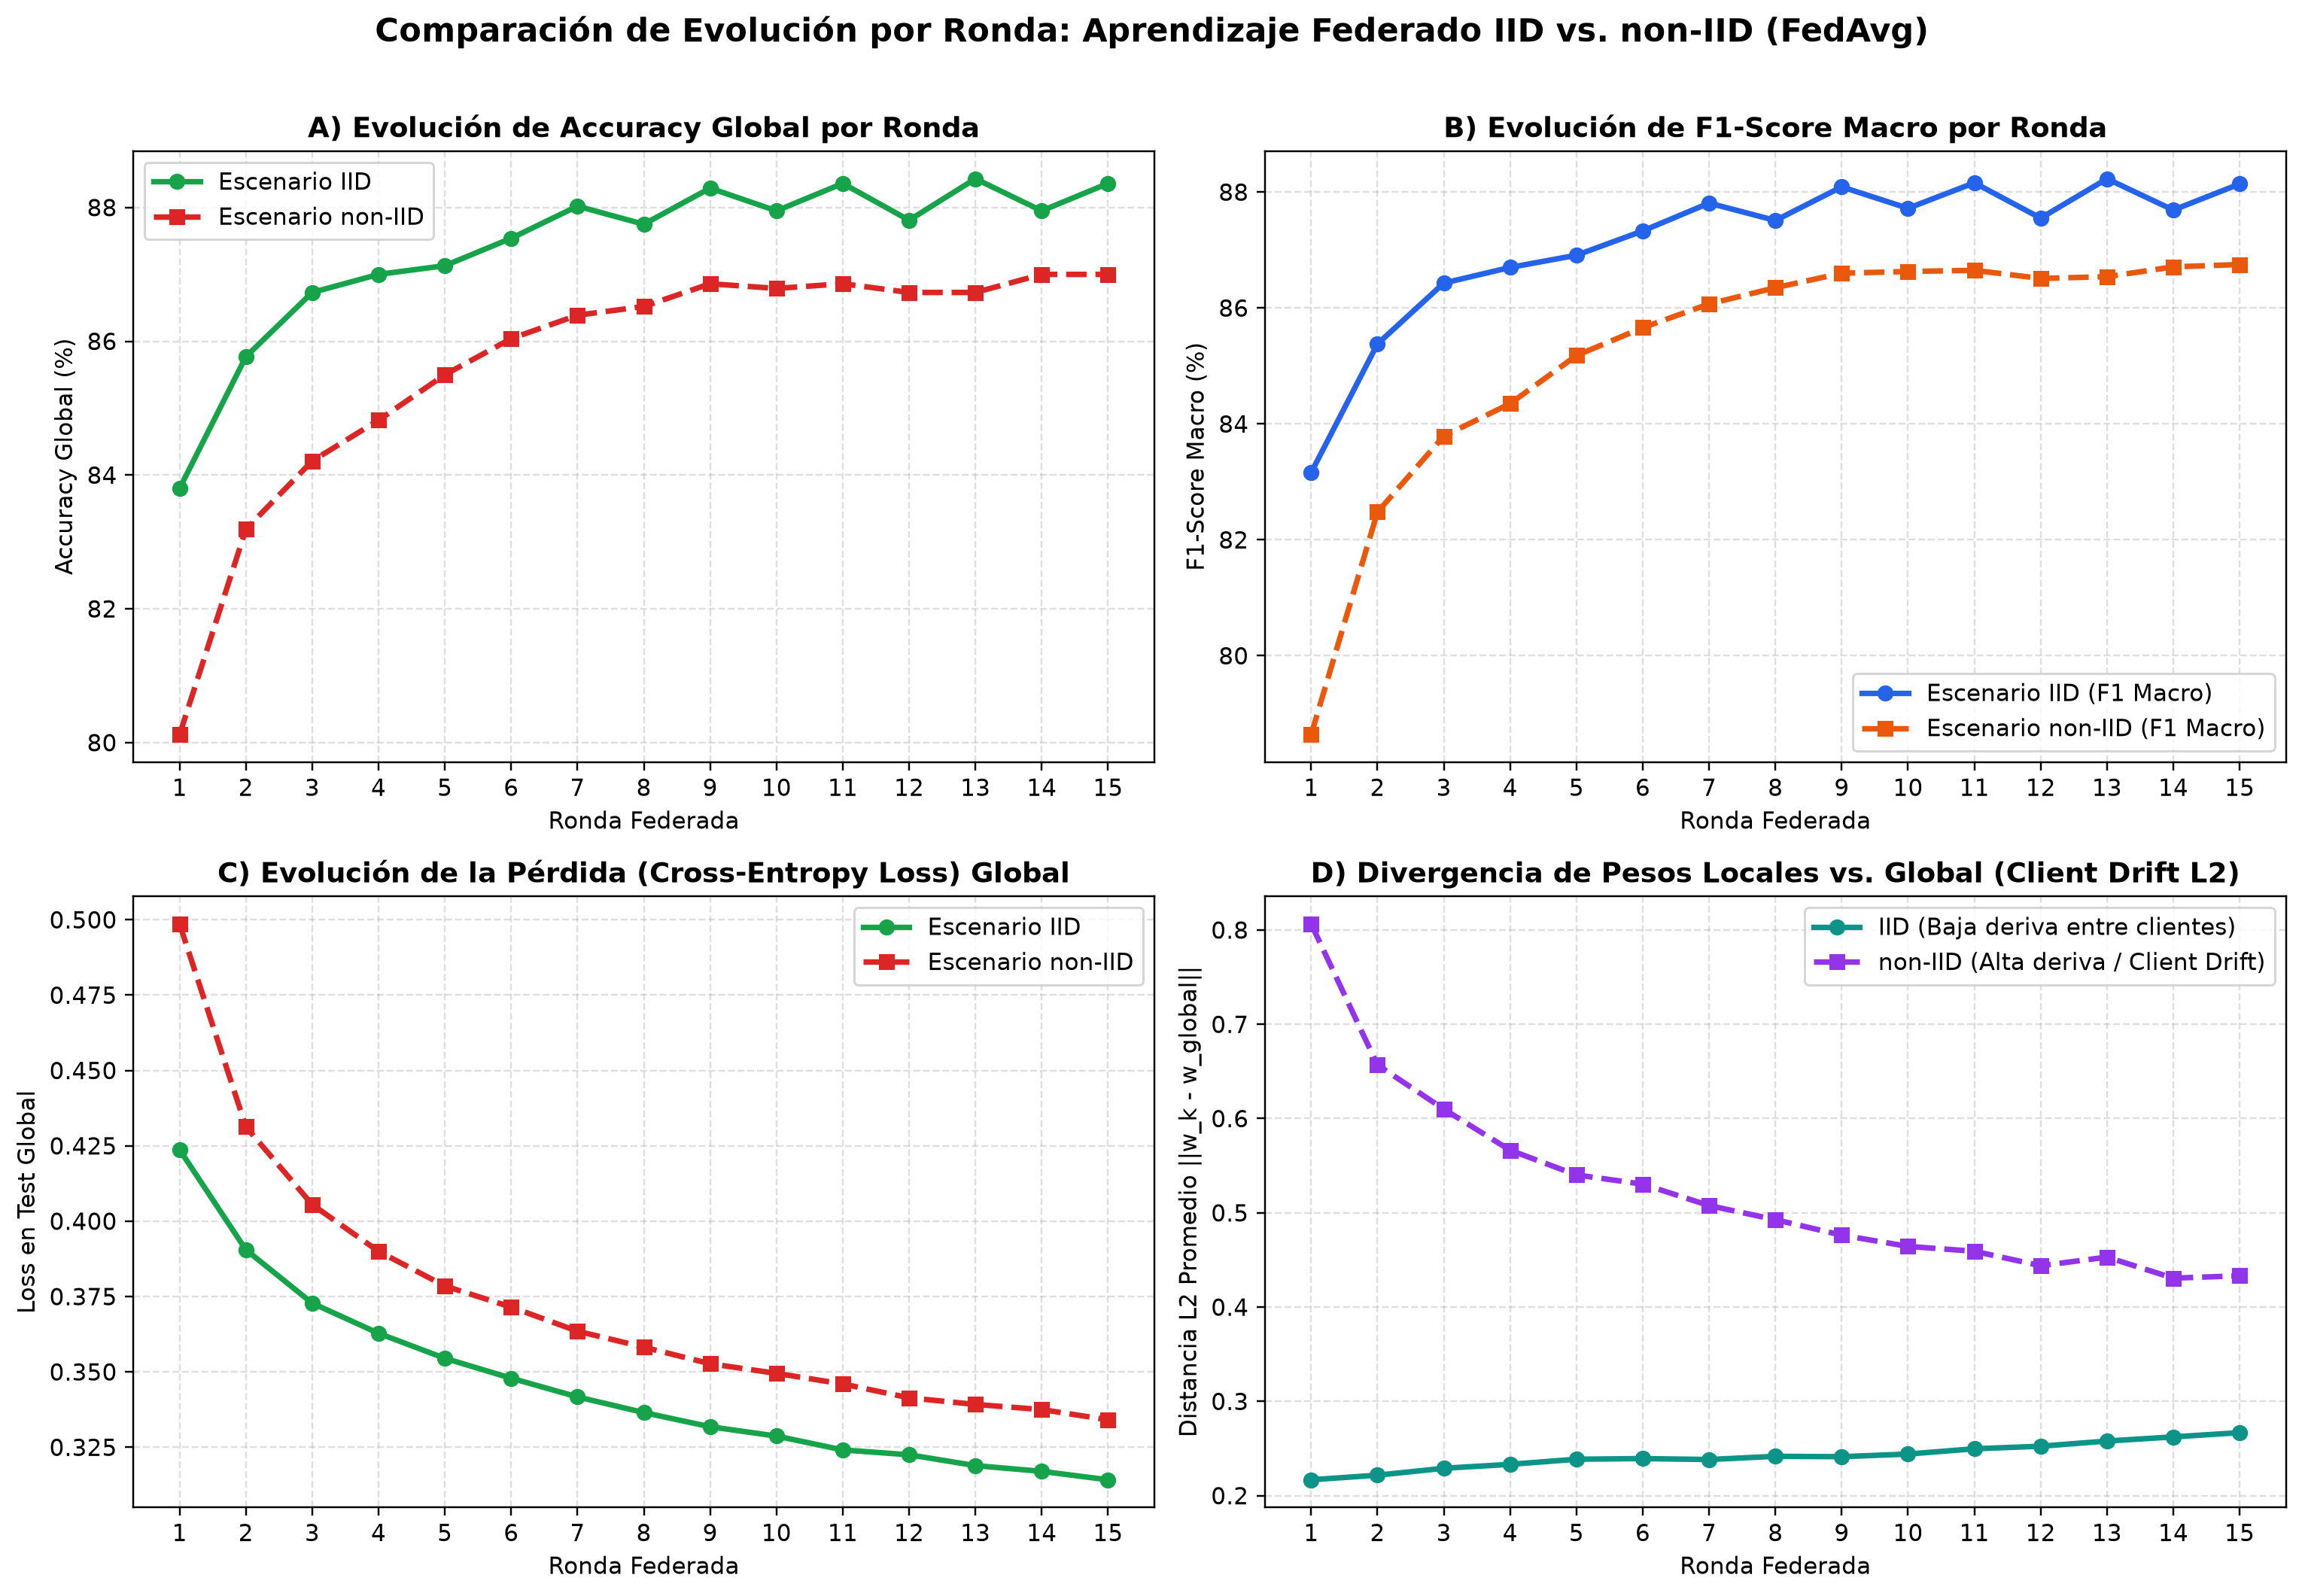

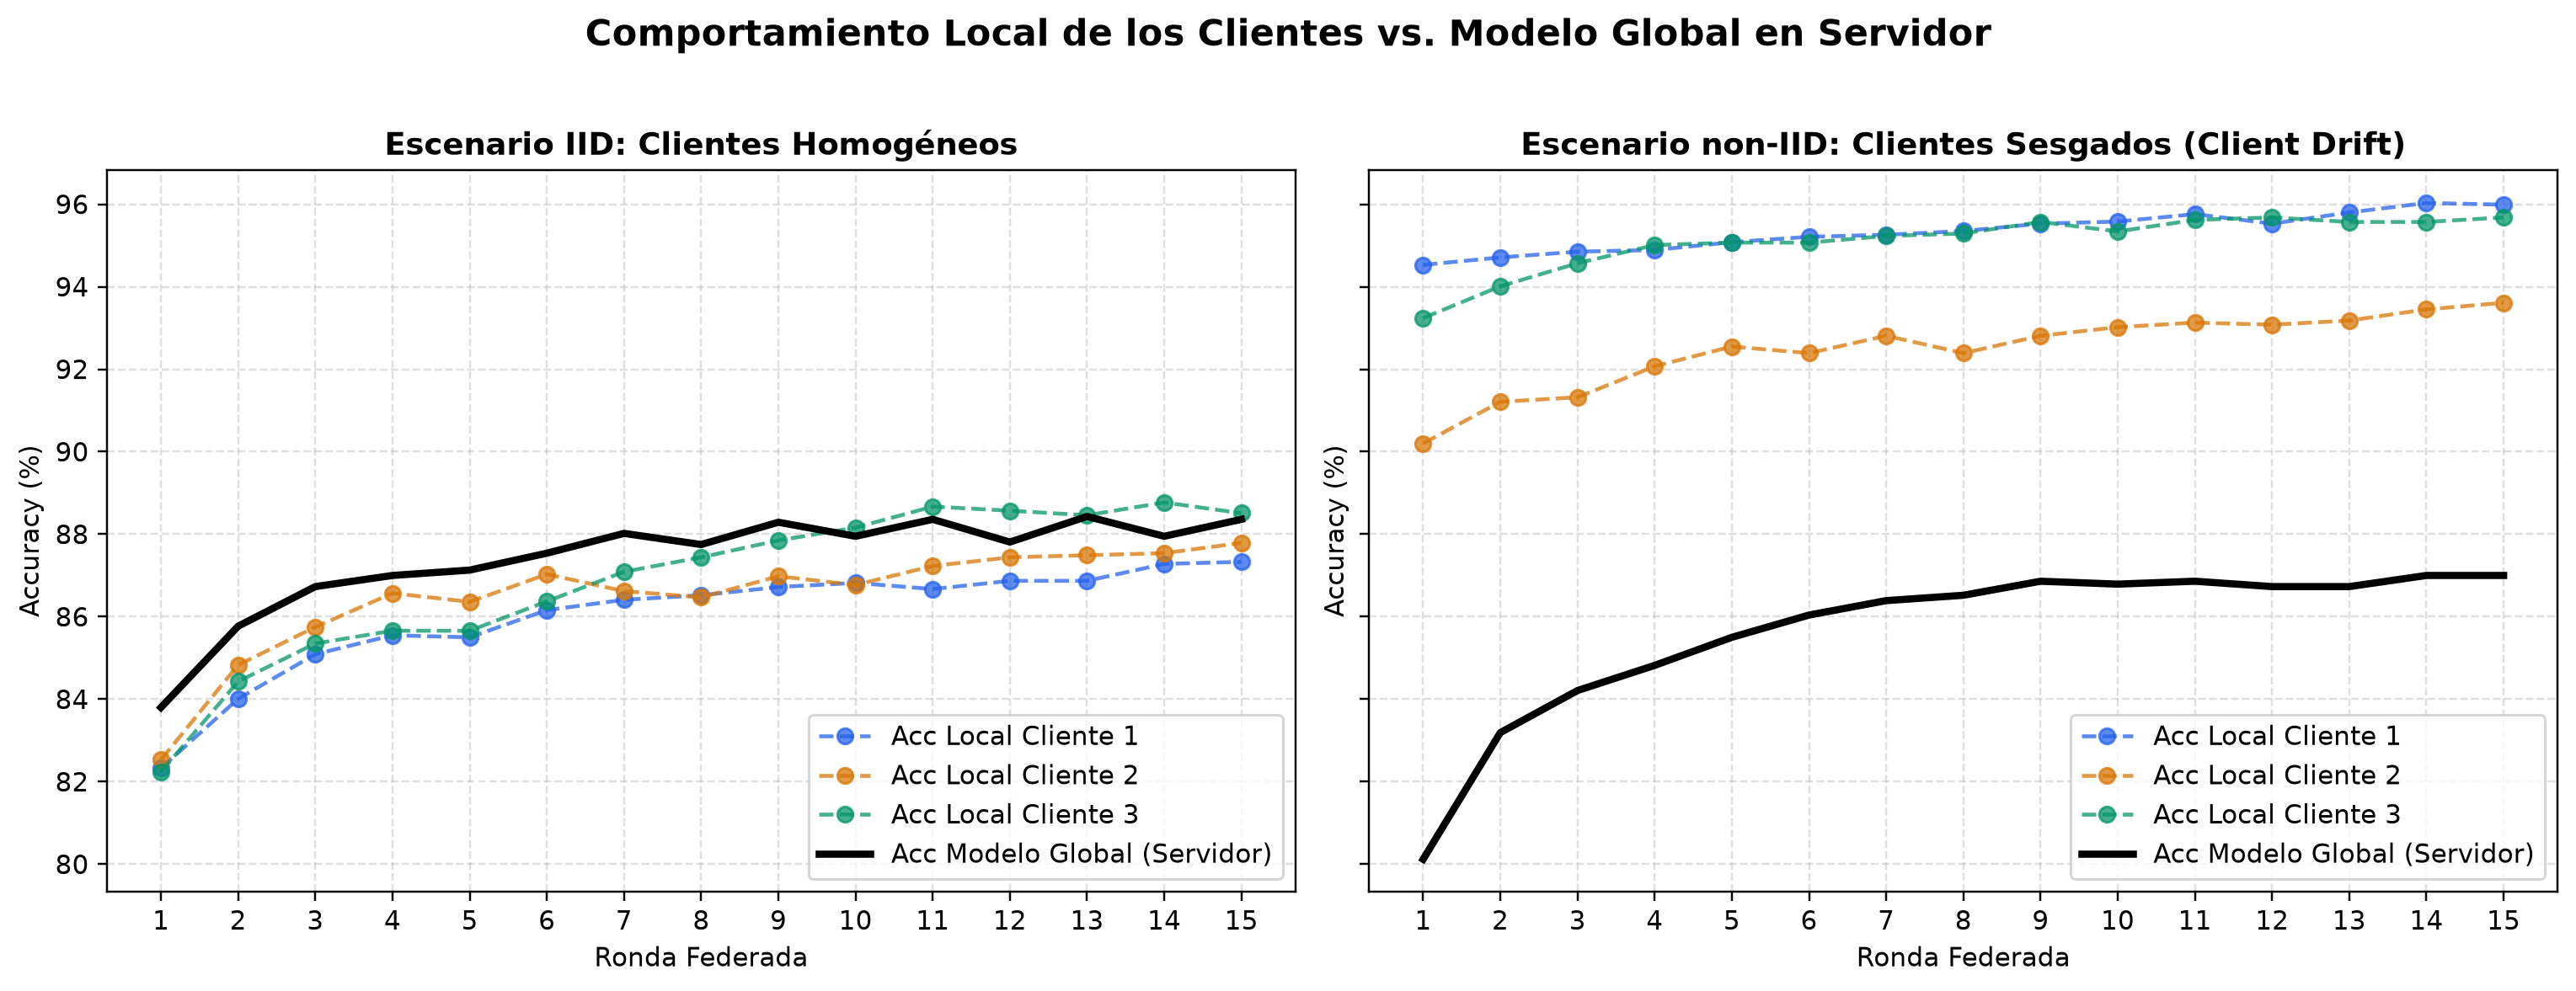

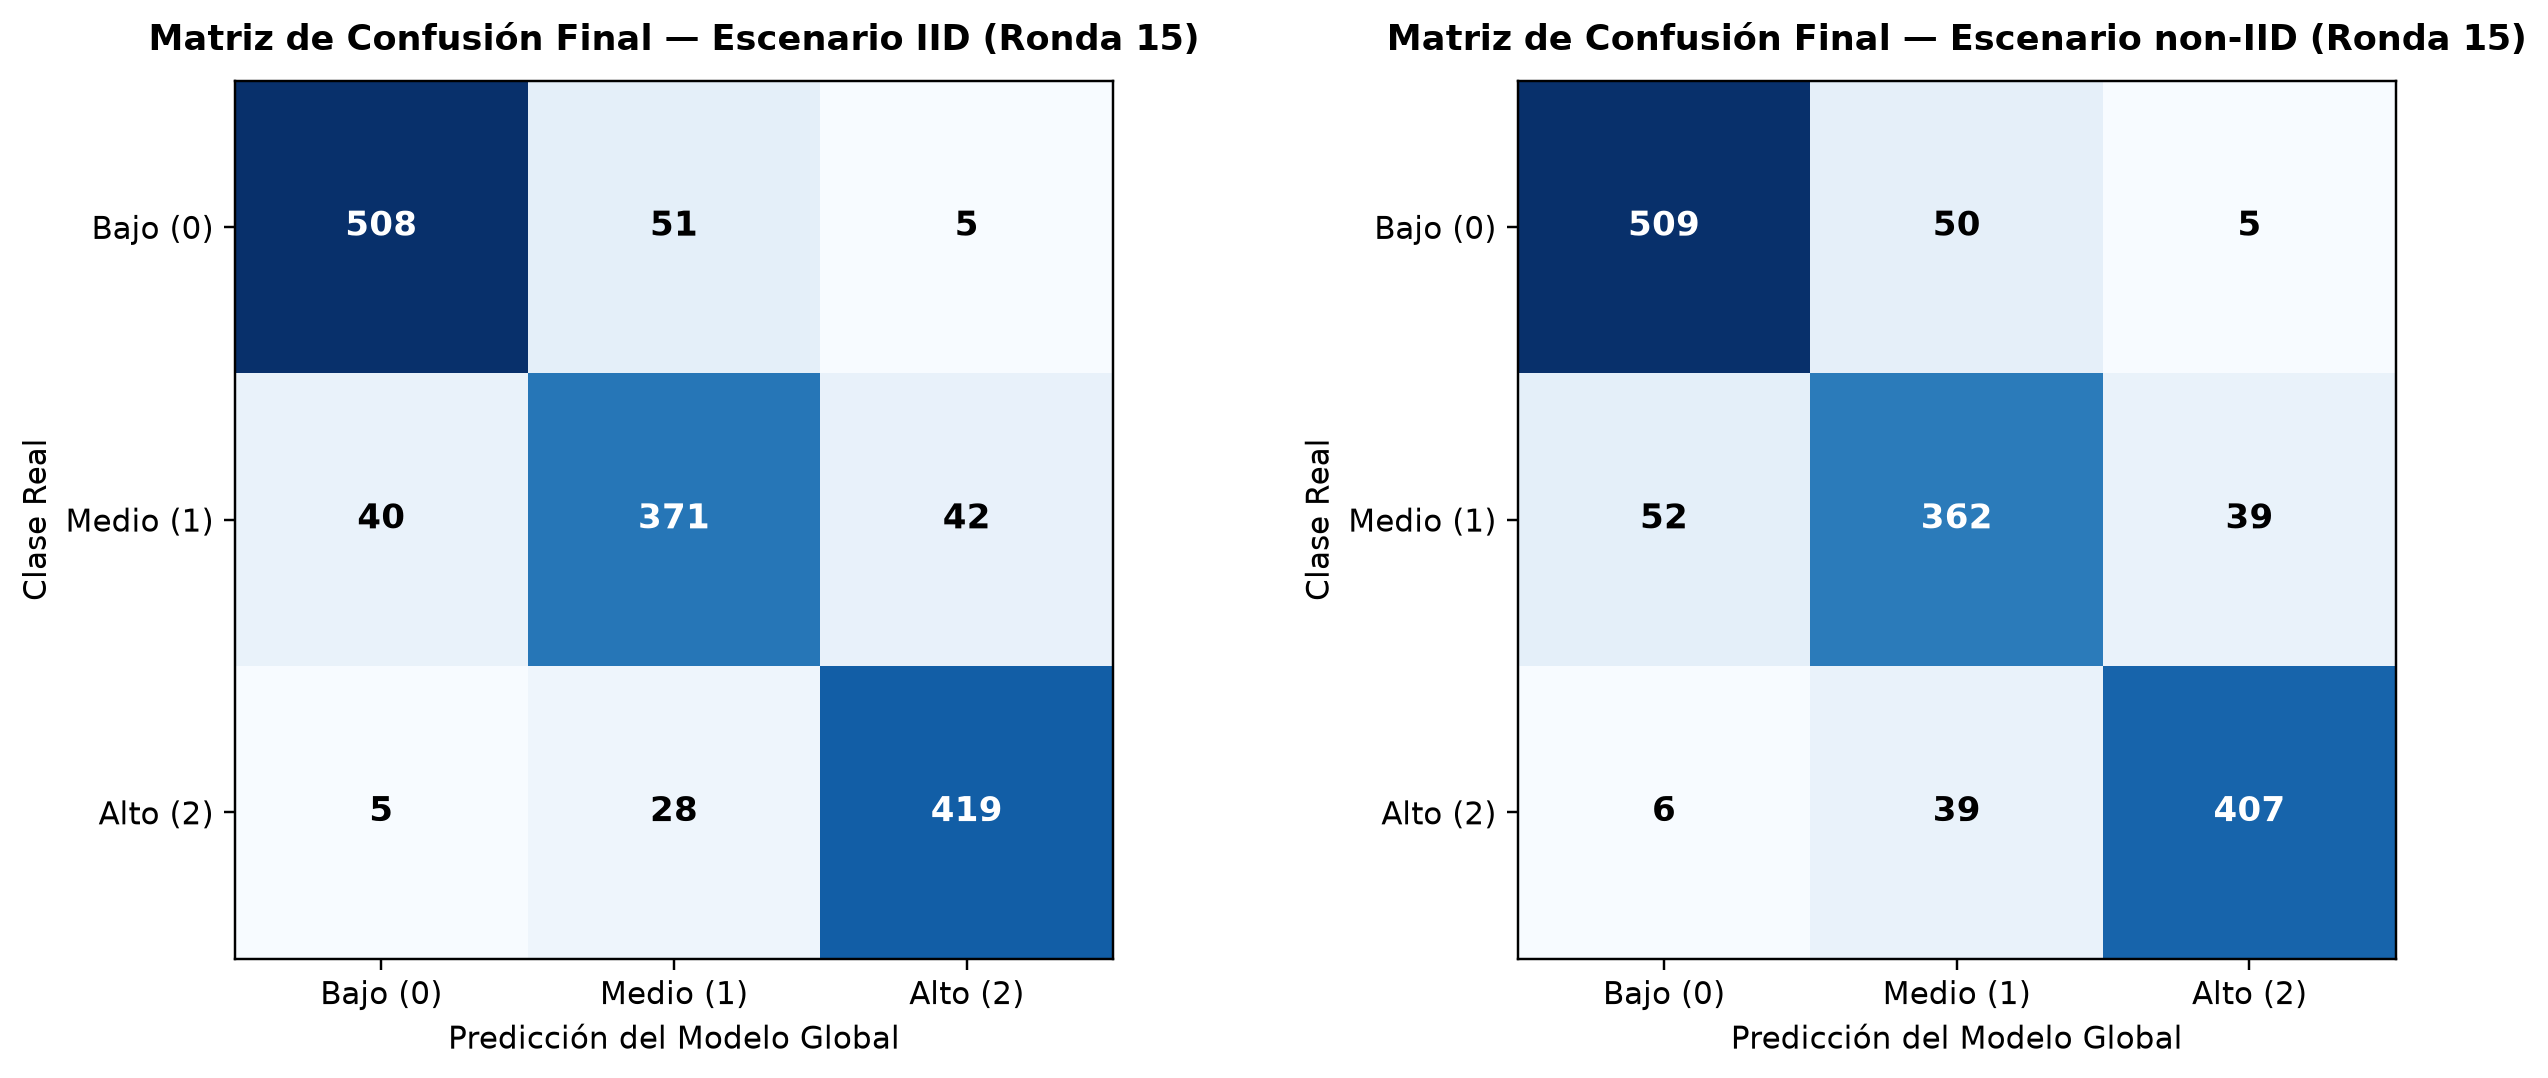

In [3]:
display(Image(filename="results/evolucion_iid_vs_non_iid.png"))
display(Image(filename="results/comportamiento_clientes_locales.png"))
display(Image(filename="results/matrices_confusion_comparativa.png"))


### Análisis de los 5 Criterios Comparativos (IID vs. non-IID)

1. **Rendimiento final (Ronda 15):**
   - El escenario **IID** alcanza **88.36% de Accuracy** y **88.14% de F1-Score Macro** (Loss = `0.3142`), superando al escenario **non-IID** que alcanza **87.00% de Accuracy** y **86.75% de F1-Score Macro** (Loss = `0.3341`), una ventaja de **+1.36 puntos porcentuales** en Accuracy y **+1.39 pp** en F1.
2. **Evolución por ronda y velocidad de convergencia:**
   - En **IID**, desde la **Ronda 1** el modelo global logra `83.80%` de Accuracy y supera la barrera del **85% en la Ronda 2** (`85.77%`).
   - En **non-IID**, la Ronda 1 arranca en `80.12%` (`78.60%` F1) y requiere **hasta la Ronda 5** (`85.50%`) para alcanzar el nivel que IID logró en la Ronda 2 (convergencia **2.5 veces más lenta** en las primeras rondas).
3. **Estabilidad y Divergencia de Pesos (*Client Drift*):**
   - La distancia L2 promedio entre los pesos locales entrenados por cada cliente y el modelo global agregado ($\|\mathbf{w}_k^{(t)} - \mathbf{w}_{\text{global}}^{(t)}\|_2$) es de **`0.5248` en non-IID** frente a **`0.2422` en IID** (**2.17 veces mayor deriva en non-IID**, llegando a `0.8055` en la Ronda 1).
4. **Comportamiento de los clientes locales:**
   - En **IID**, la exactitud local de los 3 clientes (`82% -> 88%`) avanza alineada con la exactitud del modelo global (`88.36%`).
   - En **non-IID**, cada cliente exhibe una exactitud local artificialmente alta (`93%–96%`) pero un F1 Macro local menor (`75%–82%`), porque cada red local se sobre-especializa en su clase dominante durante las épocas locales (*Client Drift*). Al promediar pesos que apuntan a mínimos locales distintos, el modelo global sufre interferencia entre gradientes.


---
## 5. Prueba de Desconexión Temporal y Recuperación de Clientes

Para verificar la tolerancia a fallos del sistema distribuido, en el tercer experimento (**Escenario non-IID con caída de red**) el **Cliente 3** (que concentra el $90.24\%$ de los datos de **Clase 2: Contaminación Alta**) pierde la conexión de red durante las **Rondas 5, 6, 7 y 8**, y vuelve a conectarse en la **Ronda 9**.

### ¿Qué ocurre en el sistema paso a paso?
1. **Detección del cliente caído:** El hilo supervisor del servidor detecta que el Cliente 3 dejó de enviar pulsos `/heartbeat` y, al cumplirse el `round_timeout`, registra:
   `[ALERTA DESCONEXION] Ronda 5 finalizada por TIMEOUT: Clientes sin respuesta -> [3]. Continuando FedAvg con clientes disponibles: [1, 2].`
2. **Continuación sin bloqueo:** El servidor **no espera indefinidamente**. Re-normaliza los pesos de `FedAvg` exclusivamente entre los Clientes 1 y 2:
   $$\alpha_1 = \frac{2193}{2193 + 1878} = 0.5387, \qquad \alpha_2 = \frac{1878}{2193 + 1878} = 0.4613$$
3. **Efecto en el modelo global durante la ausencia (Rondas 5–8):** Al faltar el Cliente 3 en un escenario non-IID, el modelo global deja de recibir gradientes representativos de la **Clase 2 (Contaminación Alta)**. Como consecuencia, el F1 de la Clase 2 cae de **87.7% (Ronda 4)** a **81.4% (Ronda 5)** y el F1 Macro global desciende de **84.36%** a **81.25% (Ronda 6)**.
4. **Reconexión y sincronización automática (Ronda 9):** Cuando el Cliente 3 recupera la red en la Ronda 9, el servidor detecta su retorno, le envía los **pesos globales actuales de la Ronda 9** (sincronizándolo instantáneamente y descartando las rondas perdidas), y reincorpora sus pesos en `FedAvg` ($\alpha_1=0.3733, \alpha_2=0.3197, \alpha_3=0.3071$). El F1 de la Clase 2 se recupera de inmediato de **82.8% a 89.0%** en una sola ronda.


,Ronda,Motivo Cierre Ronda,Clientes Activos,Clientes Desconectados,Pesos FedAvg,Acc Global (%),F1 Global (%),F1 Clase 0 Bajo (%),F1 Clase 1 Medio (%),F1 Clase 2 Alto (%)
0,1,ALL_CLIENTS_RESPONDED,"[1, 2, 3]",[],"{'client_1': 0.3733, 'client_3': 0.3071, 'clie...",80.12,78.64,85.76,63.93,86.23
1,2,ALL_CLIENTS_RESPONDED,"[1, 2, 3]",[],"{'client_1': 0.3733, 'client_3': 0.3071, 'clie...",83.19,82.48,88.03,72.07,87.34
2,3,ALL_CLIENTS_RESPONDED,"[1, 2, 3]",[],"{'client_3': 0.3071, 'client_1': 0.3733, 'clie...",84.21,83.79,89.03,75.25,87.08
3,4,ALL_CLIENTS_RESPONDED,"[1, 2, 3]",[],"{'client_1': 0.3733, 'client_3': 0.3071, 'clie...",84.82,84.35,89.49,75.90,87.67
4,5,ROUND_TIMEOUT_PARTIAL_CLIENTS,"[1, 2]",[3],"{'client_1': 0.5387, 'client_2': 0.4613}",82.44,81.90,89.86,74.44,81.41
5,6,ROUND_TIMEOUT_PARTIAL_CLIENTS,"[1, 2]",[3],"{'client_2': 0.4613, 'client_1': 0.5387}",81.82,81.26,88.52,72.69,82.59
6,7,ROUND_TIMEOUT_PARTIAL_CLIENTS,"[1, 2]",[3],"{'client_2': 0.4613, 'client_1': 0.5387}",82.51,81.97,89.04,73.86,83.02
7,8,ROUND_TIMEOUT_PARTIAL_CLIENTS,"[1, 2]",[3],"{'client_2': 0.4613, 'client_1': 0.5387}",83.12,82.68,89.69,75.49,82.85
8,9,ALL_CLIENTS_RESPONDED,"[1, 2, 3]",[],"{'client_2': 0.3197, 'client_1': 0.3733, 'clie...",86.18,85.89,89.85,78.77,89.06
9,10,ALL_CLIENTS_RESPONDED,"[1, 2, 3]",[],"{'client_2': 0.3197, 'client_1': 0.3733, 'clie...",86.39,86.17,89.73,79.39,89.39


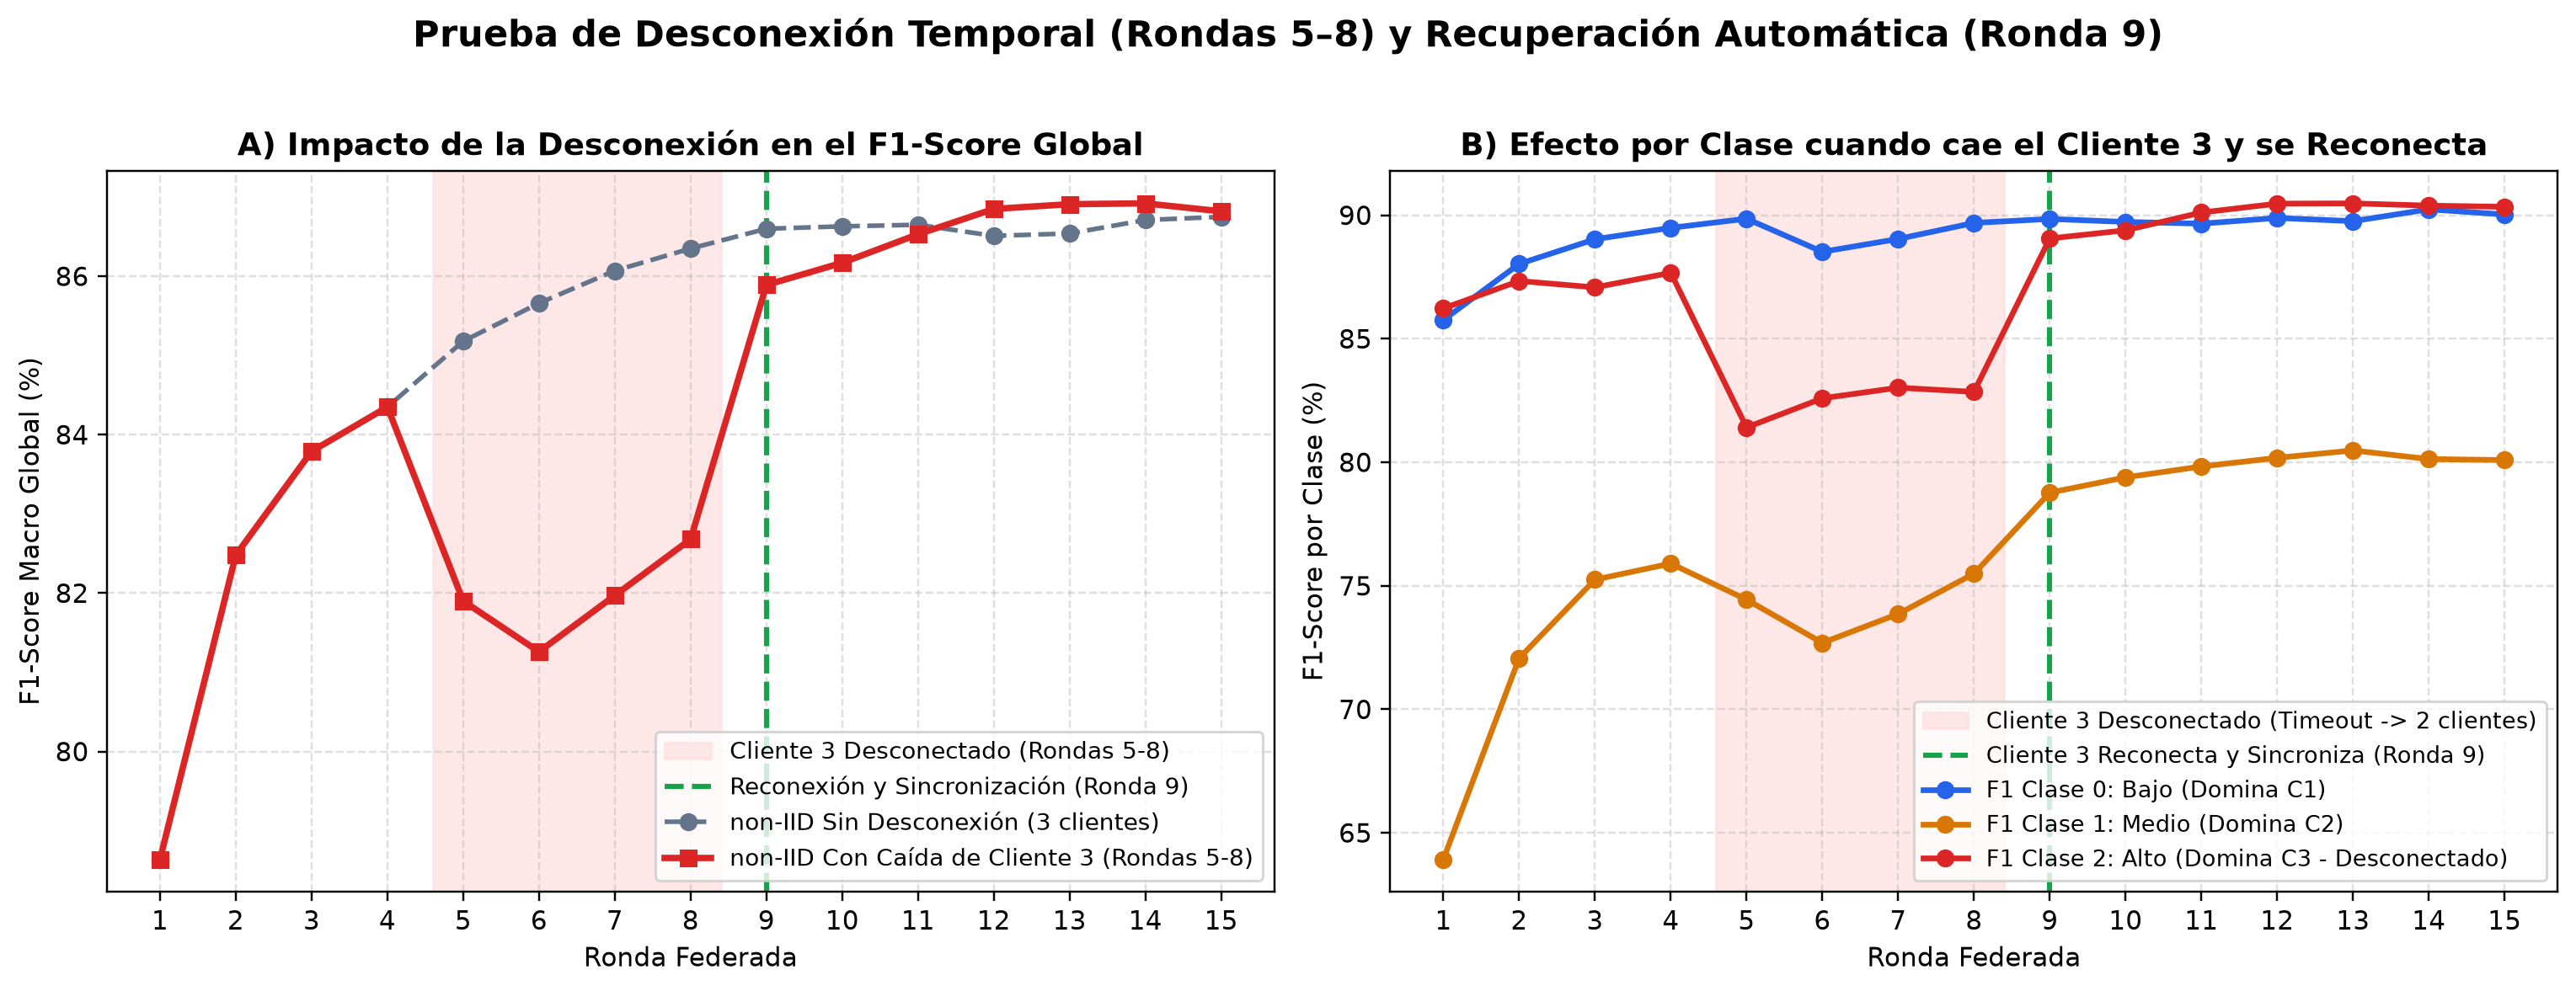

In [4]:
with open("results/history_disconnect.json", "r", encoding="utf-8") as f:
    disc_json = json.load(f)

disc_rows = []
for h in disc_json["history"]:
    gm = h["global_metrics"]
    disc_rows.append({
        "Ronda": h["round"],
        "Motivo Cierre Ronda": h["reason"],
        "Clientes Activos": str(h["active_clients"]),
        "Clientes Desconectados": str(h["missing_clients"]),
        "Pesos FedAvg": str(h["weighting_factors"]),
        "Acc Global (%)": round(gm["accuracy"] * 100, 2),
        "F1 Global (%)": round(gm["f1"] * 100, 2),
        "F1 Clase 0 Bajo (%)": round(gm["f1_per_class"][0] * 100, 2),
        "F1 Clase 1 Medio (%)": round(gm["f1_per_class"][1] * 100, 2),
        "F1 Clase 2 Alto (%)": round(gm["f1_per_class"][2] * 100, 2),
    })

display(pd.DataFrame(disc_rows))
display(Image(filename="results/prueba_desconexion_recuperacion.png"))


---
## 6. Respuesta a la Pregunta Central y Conclusiones

> **Pregunta Central:** *¿Cómo afecta una distribución non-IID al aprendizaje federado y qué ocurre cuando uno de los clientes deja temporalmente de participar?*

1. **Efecto de la distribución non-IID en el Aprendizaje Federado:**
   - Cuando los datos entre clientes no son independiente e idénticamente distribuidos (**non-IID**), cada cliente optimiza su red neuronal local hacia la distribución sesgada de sus propios datos locales, fenómeno conocido como **Client Drift (deriva de clientes)**.
   - En nuestros experimentos sobre **Air Quality**, esto provocó que la divergencia L2 entre los pesos locales y el modelo global fuera **2.17 veces mayor en non-IID (`0.5248`) que en IID (`0.2422`)**.
   - Aunque cada cliente individual alcanza una exactitud local muy alta en su clase mayoritaria ($93\%–96\%$), al promediar sus pesos mediante `FedAvg` los gradientes divergentes se cancelan parcialmente, produciendo **convergencia inicial más lenta** (Ronda 5 vs. Ronda 2 para alcanzar $85\%$ de Accuracy), mayor pérdida global (`0.3341` vs. `0.3142`) y menor F1-Score final (`86.75%` vs. `88.14%`).

2. **Efecto de la desconexión temporal de un cliente y su posterior reconexión:**
   - **A nivel de sistemas distribuidos:** Gracias al mecanismo de **Heartbeat + Timeout por ronda** implementado en `server.py`, la caída de red de un cliente no bloquea al servidor. El servidor identifica qué cliente dejó de responder, cierra la ronda al cumplirse el timeout y recalcula `FedAvg` re-normalizando los coeficientes $\alpha_k$ entre los clientes disponibles.
   - **A nivel estadístico y de aprendizaje:** El impacto de la desconexión depende directamente de si el escenario es IID o non-IID. En un escenario **IID**, la pérdida temporal de un cliente apenas altera la distribución representada por los demás clientes; en cambio, en un escenario **non-IID**, la desconexión del Cliente 3 (que posee el $90.2\%$ de los ejemplos de *Alta Contaminación*) priva temporalmente al modelo global de gradientes para esa clase, reduciendo el F1 de la Clase 2 del $87.7\%$ al $81.4\%$ (olvido parcial durante las rondas desconectadas).
   - **Recuperación:** Cuando el cliente restablece su conexión, sincroniza su modelo local descargando los pesos globales más recientes del servidor ($\mathbf{w}^{(t)}$) y se reincorpora en la siguiente agregación `FedAvg`, recuperando el rendimiento global ($86.82\%$ F1) en apenas 1–2 rondas.
